<a href="https://colab.research.google.com/github/SashaVeremchuk/Gazprom-production-forecast/blob/main/data_overview.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Обзор данных добычи месторождения Volve

Тетрадка для Google Colab: загружает Excel-файл с данными через `gdown` и делает первичный обзор
суточного и месячного листов.

## Подготовка в Colab

1. Откройте панель **Secrets** (значок ключа слева) и добавьте секрет `DATA_URL`.
2. Значение секрета — ссылка Google Drive на файл `data.xlsx` (доступ «всем, у кого есть ссылка») или просто ID файла.
3. Включите для тетрадки доступ к секрету (переключатель *Notebook access*).

При запуске вне Colab тетрадка читает локальный файл `data.xlsx` из папки `data`.

# Обзор данных добычи месторождения Volve

Тетрадка для Google Colab: загружает Excel-файл с данными через `gdown` и делает первичный обзор
суточного и месячного листов.

## Подготовка в Colab

1. Откройте панель **Secrets** (значок ключа слева) и добавьте секрет `DATA_URL`.
2. Значение секрета — ссылка Google Drive на файл `data.xlsx` (доступ «всем, у кого есть ссылка») или просто ID файла.
3. Включите для тетрадки доступ к секрету (переключатель *Notebook access*).

При запуске вне Colab тетрадка читает локальный файл `data.xlsx` из папки `data`.

# Обзор данных добычи месторождения Volve

Тетрадка для Google Colab: загружает Excel-файл с данными через `gdown` и делает первичный обзор
суточного и месячного листов.

## Подготовка в Colab

1. Откройте панель **Secrets** (значок ключа слева) и добавьте секрет `DATA_URL`.
2. Значение секрета — ссылка Google Drive на файл `data.xlsx` (доступ «всем, у кого есть ссылка») или просто ID файла.
3. Включите для тетрадки доступ к секрету (переключатель *Notebook access*).

При запуске вне Colab тетрадка читает локальный файл `data.xlsx` из папки `data`.

# Обзор данных добычи месторождения Volve

Тетрадка для Google Colab: загружает Excel-файл с данными через `gdown` и делает первичный обзор
суточного и месячного листов.

## Подготовка в Colab

1. Откройте панель **Secrets** (значок ключа слева) и добавьте секрет `DATA_URL`.
2. Значение секрета — ссылка Google Drive на файл `data.xlsx` (доступ «всем, у кого есть ссылка») или просто ID файла.
3. Включите для тетрадки доступ к секрету (переключатель *Notebook access*).

При запуске вне Colab тетрадка читает локальный файл `data.xlsx` из папки `data`.

# Обзор данных добычи месторождения Volve

Тетрадка для Google Colab: загружает Excel-файл с данными через `gdown` и делает первичный обзор
суточного и месячного листов.

## Подготовка в Colab

1. Откройте панель **Secrets** (значок ключа слева) и добавьте секрет `DATA_URL`.
2. Значение секрета — ссылка Google Drive на файл `data.xlsx` (доступ «всем, у кого есть ссылка») или просто ID файла.
3. Включите для тетрадки доступ к секрету (переключатель *Notebook access*).

При запуске вне Colab тетрадка читает локальный файл `data.xlsx` из папки `data`.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["axes.grid"] = True

## Загрузка файла

In [3]:
DATA_FILE = Path("data.xlsx")
SECRET_NAME = "DATA_URL"

try:
    from google.colab import userdata
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    import gdown

    data_url = (userdata.get(SECRET_NAME) or "").strip()
    if not data_url:
        raise ValueError(f"Секрет {SECRET_NAME} пуст: укажите ссылку Google Drive или ID файла.")

    if not DATA_FILE.exists():
        if data_url.startswith("http"):
            gdown.download(url=data_url, output=str(DATA_FILE), quiet=False, fuzzy=True)
        else:
            gdown.download(id=data_url, output=str(DATA_FILE), quiet=False)
else:
    # Локальный запуск: файл лежит рядом с тетрадкой, в папке data
    if not DATA_FILE.exists() and Path("data", DATA_FILE).exists():
        DATA_FILE = Path("data", DATA_FILE)

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Файл {DATA_FILE.resolve()} не найден.")

print(f"Файл: {DATA_FILE.resolve()} ({DATA_FILE.stat().st_size / 1024**2:.1f} МБ)")

Downloading...
From: https://drive.google.com/uc?id=1--ZBtZ_h81gJTpKtB7fMj5J3GAcAiN3w
To: /content/data.xlsx
100%|██████████| 2.35M/2.35M [00:00<00:00, 41.2MB/s]

Файл: /content/data.xlsx (2.2 МБ)


## Чтение листов

In [4]:
xls = pd.ExcelFile(DATA_FILE)
print("Листы:", xls.sheet_names)

DAILY_SHEET = "Daily Production Data"
MONTHLY_SHEET = "Monthly Production Data"
DESCR_SHEET = "Описание колонок"

daily_raw = pd.read_excel(xls, DAILY_SHEET)
monthly_raw = pd.read_excel(xls, MONTHLY_SHEET)
descr_raw = pd.read_excel(xls, DESCR_SHEET) if DESCR_SHEET in xls.sheet_names else None

for name, df in [(DAILY_SHEET, daily_raw), (MONTHLY_SHEET, monthly_raw)]:
    print(f"{name}: {df.shape[0]:,} строк × {df.shape[1]} колонок")

Листы: ['Daily Production Data', 'Monthly Production Data', 'Описание колонок']
Daily Production Data: 15,634 строк × 24 колонок
Monthly Production Data: 527 строк × 10 колонок


### Описание колонок

Лист с описанием содержит две таблицы подряд (месячные и суточные колонки), разделённые пустыми строками
и повторным заголовком. Собираем их в один справочник.

In [5]:
if descr_raw is not None:
    descr = descr_raw.rename(columns=str.strip).dropna(how="all")
    descr = descr.apply(lambda s: s.str.strip() if s.dtype == object or pd.api.types.is_string_dtype(s) else s)
    header = descr.columns.tolist()
    descr = descr[descr[header[0]] != header[0]].reset_index(drop=True)
    descr["Лист"] = np.where(descr[header[0]].isin(monthly_raw.columns), MONTHLY_SHEET, DAILY_SHEET)
    col_info = descr.set_index(header[0])
    display(descr)
else:
    col_info = pd.DataFrame()
    print("Лист с описанием колонок отсутствует.")

,Исходная колонка,Русское название,Единица,Описание,Лист
0,Wellbore name,Название ствола скважины,—,Идентификатор ствола.,Monthly Production Data
1,NPDCode,Код ствола в NPD,—,Числовой идентификатор NPD.,Monthly Production Data
2,Year,Год,—,Год производственного отчёта.,Monthly Production Data
3,Month,Месяц,—,Номер календарного месяца.,Monthly Production Data
4,On Stream,Время работы за месяц,ч,Суммарное время работы скважины в соответствую...,Monthly Production Data
5,Oil,Месячная добыча нефти,ст. м³,Добыча нефти за месяц.,Monthly Production Data
6,Gas,Месячная добыча газа,ст. м³,Добыча газа за месяц.,Monthly Production Data
7,Water,Месячная добыча воды,ст. м³,Попутно добытая вода за месяц.,Monthly Production Data
8,GI,Месячная закачка газа,ст. м³,Месячная закачка газа,Monthly Production Data
9,WI,Месячная закачка воды,ст. м³,Месячная закачка воды,Monthly Production Data


## Суточные данные

### Структура и пропуски

In [6]:
daily = daily_raw.copy()
daily["DATEPRD"] = pd.to_datetime(daily["DATEPRD"])
daily = daily.sort_values(["NPD_WELL_BORE_NAME", "DATEPRD"]).reset_index(drop=True)

overview = pd.DataFrame({
    "dtype": daily.dtypes.astype(str),
    "непустых": daily.notna().sum(),
    "пропусков, %": daily.isna().mean() * 100,
    "уникальных": daily.nunique(),
})
if not col_info.empty:
    overview = overview.join(col_info[["Русское название", "Единица"]])
overview

,dtype,непустых,"пропусков, %",уникальных,Русское название,Единица
DATEPRD,datetime64[ns],15634,0.00,3327,Дата добычи,—
WELL_BORE_CODE,object,15634,0.00,7,Код ствола скважины,—
NPD_WELL_BORE_CODE,int64,15634,0.00,7,Код ствола в NPD,—
NPD_WELL_BORE_NAME,object,15634,0.00,7,Название ствола в NPD,—
NPD_FIELD_CODE,int64,15634,0.00,1,Код месторождения в NPD,—
NPD_FIELD_NAME,object,15634,0.00,1,Название месторождения,—
NPD_FACILITY_CODE,int64,15634,0.00,1,Код производственного объекта,—
NPD_FACILITY_NAME,object,15634,0.00,1,Название производственного объекта,—
ON_STREAM_HRS,float64,15349,1.82,925,Время работы за сутки,ч
AVG_DOWNHOLE_PRESSURE,float64,8980,42.56,6567,Среднее забойное давление,бар


In [7]:
daily.head()

,DATEPRD,WELL_BORE_CODE,NPD_WELL_BORE_CODE,NPD_WELL_BORE_NAME,NPD_FIELD_CODE,NPD_FIELD_NAME,NPD_FACILITY_CODE,NPD_FACILITY_NAME,ON_STREAM_HRS,AVG_DOWNHOLE_PRESSURE,AVG_DOWNHOLE_TEMPERATURE,AVG_DP_TUBING,AVG_ANNULUS_PRESS,AVG_CHOKE_SIZE_P,AVG_CHOKE_UOM,AVG_WHP_P,AVG_WHT_P,DP_CHOKE_SIZE,BORE_OIL_VOL,BORE_GAS_VOL,BORE_WAT_VOL,BORE_WI_VOL,FLOW_KIND,WELL_TYPE
0,2014-04-07,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.00,0.00,0.00,0.00,0.00,0.00,%,0.00,0.00,0.00,0.00,0.00,0.00,NaN,production,WI
1,2014-04-08,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.00,NaN,NaN,NaN,0.00,1.00,%,0.00,0.00,0.00,0.00,0.00,0.00,NaN,production,OP
2,2014-04-09,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.00,NaN,NaN,NaN,0.00,0.98,%,0.00,0.00,0.00,0.00,0.00,0.00,NaN,production,OP
3,2014-04-10,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.00,NaN,NaN,NaN,0.00,0.55,%,0.00,0.00,0.00,0.00,0.00,0.00,NaN,production,OP
4,2014-04-11,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.00,310.38,96.88,277.28,0.00,1.22,%,33.10,10.48,33.07,0.00,0.00,0.00,NaN,production,OP


Константные колонки (одно значение на весь набор) — кандидаты на удаление:

In [8]:
constant_cols = [c for c in daily.columns if daily[c].nunique(dropna=False) == 1]
daily[constant_cols].iloc[0] if constant_cols else "нет"

,0
NPD_FIELD_CODE,3420717
NPD_FIELD_NAME,VOLVE
NPD_FACILITY_CODE,369304
NPD_FACILITY_NAME,MÆRSK INSPIRER


In [9]:
NUM_COLS = daily.select_dtypes("number").columns.difference(
    ["NPD_WELL_BORE_CODE", "NPD_FIELD_CODE", "NPD_FACILITY_CODE"]
).tolist()
daily[NUM_COLS].describe().T

,count,mean,std,min,25%,50%,75%,max
AVG_ANNULUS_PRESS,"7,890.00",14.86,8.41,0.00,10.84,16.31,21.31,30.02
AVG_CHOKE_SIZE_P,"8,919.00",55.17,36.69,0.00,18.95,52.10,99.92,100.00
AVG_DOWNHOLE_PRESSURE,"8,980.00",181.80,109.71,0.00,0.00,232.90,255.40,397.59
AVG_DOWNHOLE_TEMPERATURE,"8,980.00",77.16,45.66,0.00,0.00,103.19,106.28,108.50
AVG_DP_TUBING,"8,980.00",154.03,76.75,0.00,83.67,175.59,204.32,345.91
AVG_WHP_P,"9,155.00",45.38,24.75,0.00,31.15,37.93,57.10,137.31
AVG_WHT_P,"9,146.00",67.73,27.72,0.00,56.58,80.07,88.06,93.51
BORE_GAS_VOL,"9,161.00","161,049.06","188,136.41",0.00,"29,430.59","87,749.66","202,482.30","851,131.52"
BORE_OIL_VOL,"9,161.00","1,095.63","1,323.54",0.00,190.69,557.55,"1,345.20","5,901.84"
BORE_WAT_VOL,"9,161.00","1,672.15","1,706.98",-457.84,19.87,"1,097.79","3,260.95","8,019.74"


### Скважины: периоды работы, тип и вид операции

In [10]:
wells = daily.groupby("NPD_WELL_BORE_NAME").agg(
    записей=("DATEPRD", "size"),
    начало=("DATEPRD", "min"),
    конец=("DATEPRD", "max"),
    тип=("WELL_TYPE", lambda s: ", ".join(sorted(s.unique()))),
    операция=("FLOW_KIND", lambda s: ", ".join(sorted(s.unique()))),
    нефть_ст_м3=("BORE_OIL_VOL", "sum"),
    газ_ст_м3=("BORE_GAS_VOL", "sum"),
    вода_ст_м3=("BORE_WAT_VOL", "sum"),
    закачка_воды_ст_м3=("BORE_WI_VOL", "sum"),
)
wells["дней_в_периоде"] = (wells["конец"] - wells["начало"]).dt.days + 1
wells["пропущено_дат"] = wells["дней_в_периоде"] - wells["записей"]

# Постоянный цвет для каждой скважины на всех графиках
WELL_COLORS = dict(zip(wells.index, plt.cm.tab10.colors))
wells

,записей,начало,конец,тип,операция,нефть_ст_м3,газ_ст_м3,вода_ст_м3,закачка_воды_ст_м3,дней_в_периоде,пропущено_дат
NPD_WELL_BORE_NAME,,,,,,,,,,,
15/9-F-1 C,746,2014-04-07,2016-04-21,"OP, WI",production,"177,709.33","26,440,918.60","207,302.39",0.00,746,0
15/9-F-11,1165,2013-07-08,2016-09-17,OP,production,"1,147,849.10","174,310,520.61","1,090,806.27",0.00,1168,3
15/9-F-12,3056,2008-02-12,2016-09-17,OP,production,"4,579,609.55","667,542,278.02","6,833,320.37",0.00,3141,85
15/9-F-14,3056,2008-02-12,2016-09-17,OP,production,"3,942,233.39","578,009,542.02","7,121,249.74",0.00,3141,85
15/9-F-15 D,978,2014-01-12,2016-09-17,OP,production,"148,518.56","22,505,350.95","52,366.40",0.00,980,2
15/9-F-4,3327,2007-09-01,2016-12-01,WI,injection,0.00,0.00,0.00,"16,240,727.04",3380,53
15/9-F-5,3306,2007-09-01,2016-09-18,"OP, WI","injection, production","41,160.68","6,561,825.74","13,533.18","14,089,406.49",3306,0


In [11]:
pd.crosstab(daily["NPD_WELL_BORE_NAME"], [daily["FLOW_KIND"], daily["WELL_TYPE"]])

FLOW_KIND          injection production    
WELL_TYPE                 WI         OP  WI
NPD_WELL_BORE_NAME                         
15/9-F-1 C                 0        744   2
15/9-F-11                  0       1165   0
15/9-F-12                  0       3056   0
15/9-F-14                  0       3056   0
15/9-F-15 D                0        978   0
15/9-F-4                3327          0   0
15/9-F-5                3146        144  16

### Карта пропусков по скважинам (доля пропусков в колонке, %)

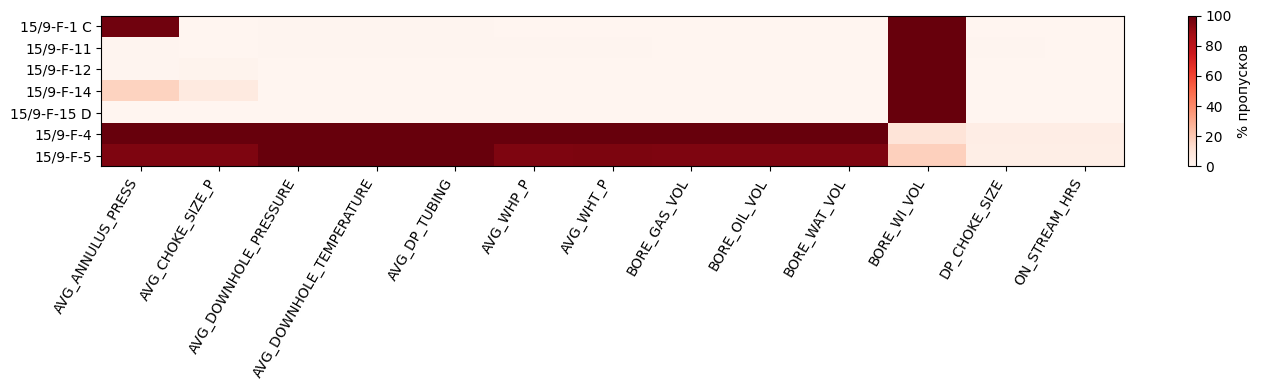

In [12]:
na_by_well = daily.groupby("NPD_WELL_BORE_NAME")[NUM_COLS].agg(lambda s: s.isna().mean() * 100)

fig, ax = plt.subplots(figsize=(14, 4))
im = ax.imshow(na_by_well.values, aspect="auto", cmap="Reds", vmin=0, vmax=100)
ax.set_xticks(range(len(NUM_COLS)), NUM_COLS, rotation=60, ha="right")
ax.set_yticks(range(len(na_by_well)), na_by_well.index)
ax.grid(False)
fig.colorbar(im, ax=ax, label="% пропусков")
plt.tight_layout()
plt.show()

### Проверки качества

In [13]:
checks = {
    "дубликаты (скважина, дата)": daily.duplicated(["NPD_WELL_BORE_NAME", "DATEPRD"]).sum(),
    "ON_STREAM_HRS > 24": (daily["ON_STREAM_HRS"] > 24).sum(),
    "ON_STREAM_HRS < 0": (daily["ON_STREAM_HRS"] < 0).sum(),
    "отрицательные объёмы": (daily[["BORE_OIL_VOL", "BORE_GAS_VOL", "BORE_WAT_VOL", "BORE_WI_VOL"]] < 0).sum().sum(),
    "добыча при ON_STREAM_HRS = 0": ((daily["ON_STREAM_HRS"] == 0) & (daily["BORE_OIL_VOL"] > 0)).sum(),
    "давление на забое = 0": (daily["AVG_DOWNHOLE_PRESSURE"] == 0).sum(),
    "отрицательные давления/перепады": (
        daily[["AVG_DOWNHOLE_PRESSURE", "AVG_DP_TUBING", "AVG_ANNULUS_PRESS", "AVG_WHP_P", "DP_CHOKE_SIZE"]] < 0
    ).sum().sum(),
}
pd.Series(checks, name="строк").to_frame()

,строк
"дубликаты (скважина, дата)",0
ON_STREAM_HRS > 24,20
ON_STREAM_HRS < 0,0
отрицательные объёмы,4
добыча при ON_STREAM_HRS = 0,1
давление на забое = 0,2312
отрицательные давления/перепады,0


### Суточная добыча и закачка по скважинам

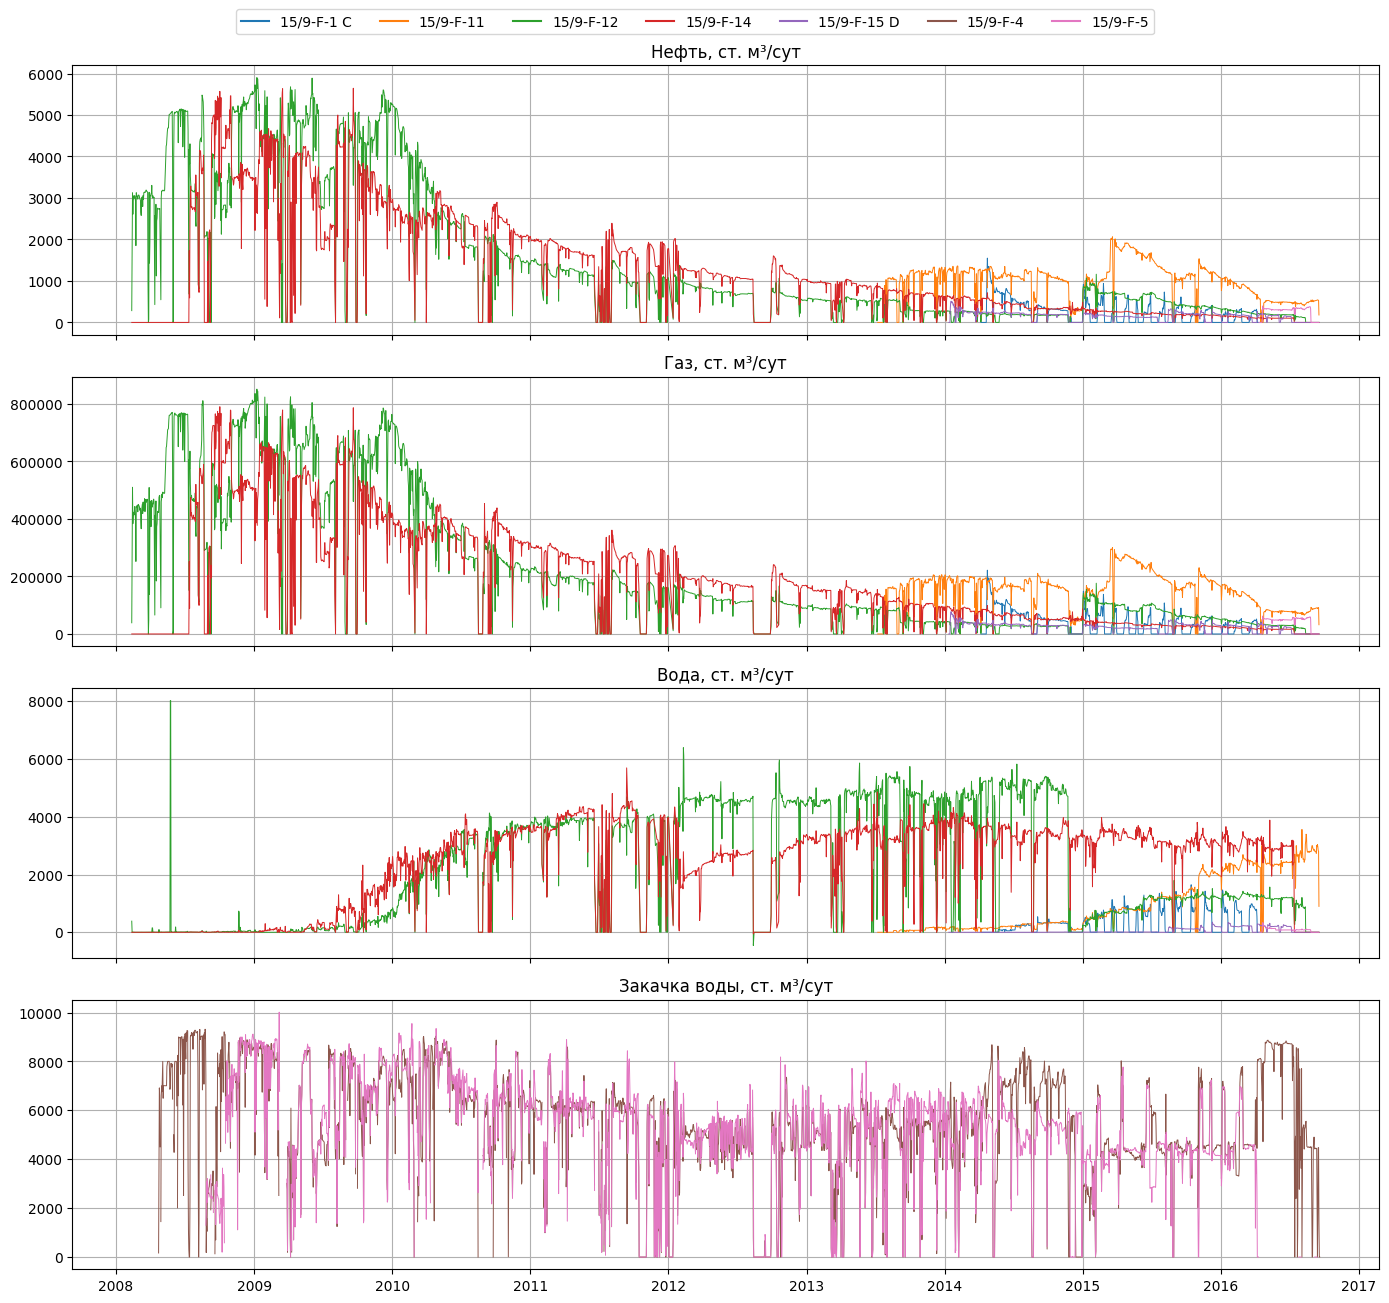

In [14]:
series = [
    ("BORE_OIL_VOL", "Нефть, ст. м³/сут"),
    ("BORE_GAS_VOL", "Газ, ст. м³/сут"),
    ("BORE_WAT_VOL", "Вода, ст. м³/сут"),
    ("BORE_WI_VOL", "Закачка воды, ст. м³/сут"),
]

fig, axes = plt.subplots(len(series), 1, figsize=(14, 3.2 * len(series)), sharex=True)
for ax, (col, title) in zip(axes, series):
    for well, g in daily.groupby("NPD_WELL_BORE_NAME"):
        if g[col].fillna(0).abs().sum() > 0:
            ax.plot(g["DATEPRD"], g[col], lw=0.7, color=WELL_COLORS[well], label=well)
    ax.set_title(title)
fig.legend(handles=[plt.Line2D([], [], color=c, label=w) for w, c in WELL_COLORS.items()],
           ncol=len(WELL_COLORS), loc="upper center", bbox_to_anchor=(0.5, 1.02))
plt.tight_layout()
plt.show()

### Давления, температуры и штуцер по скважинам

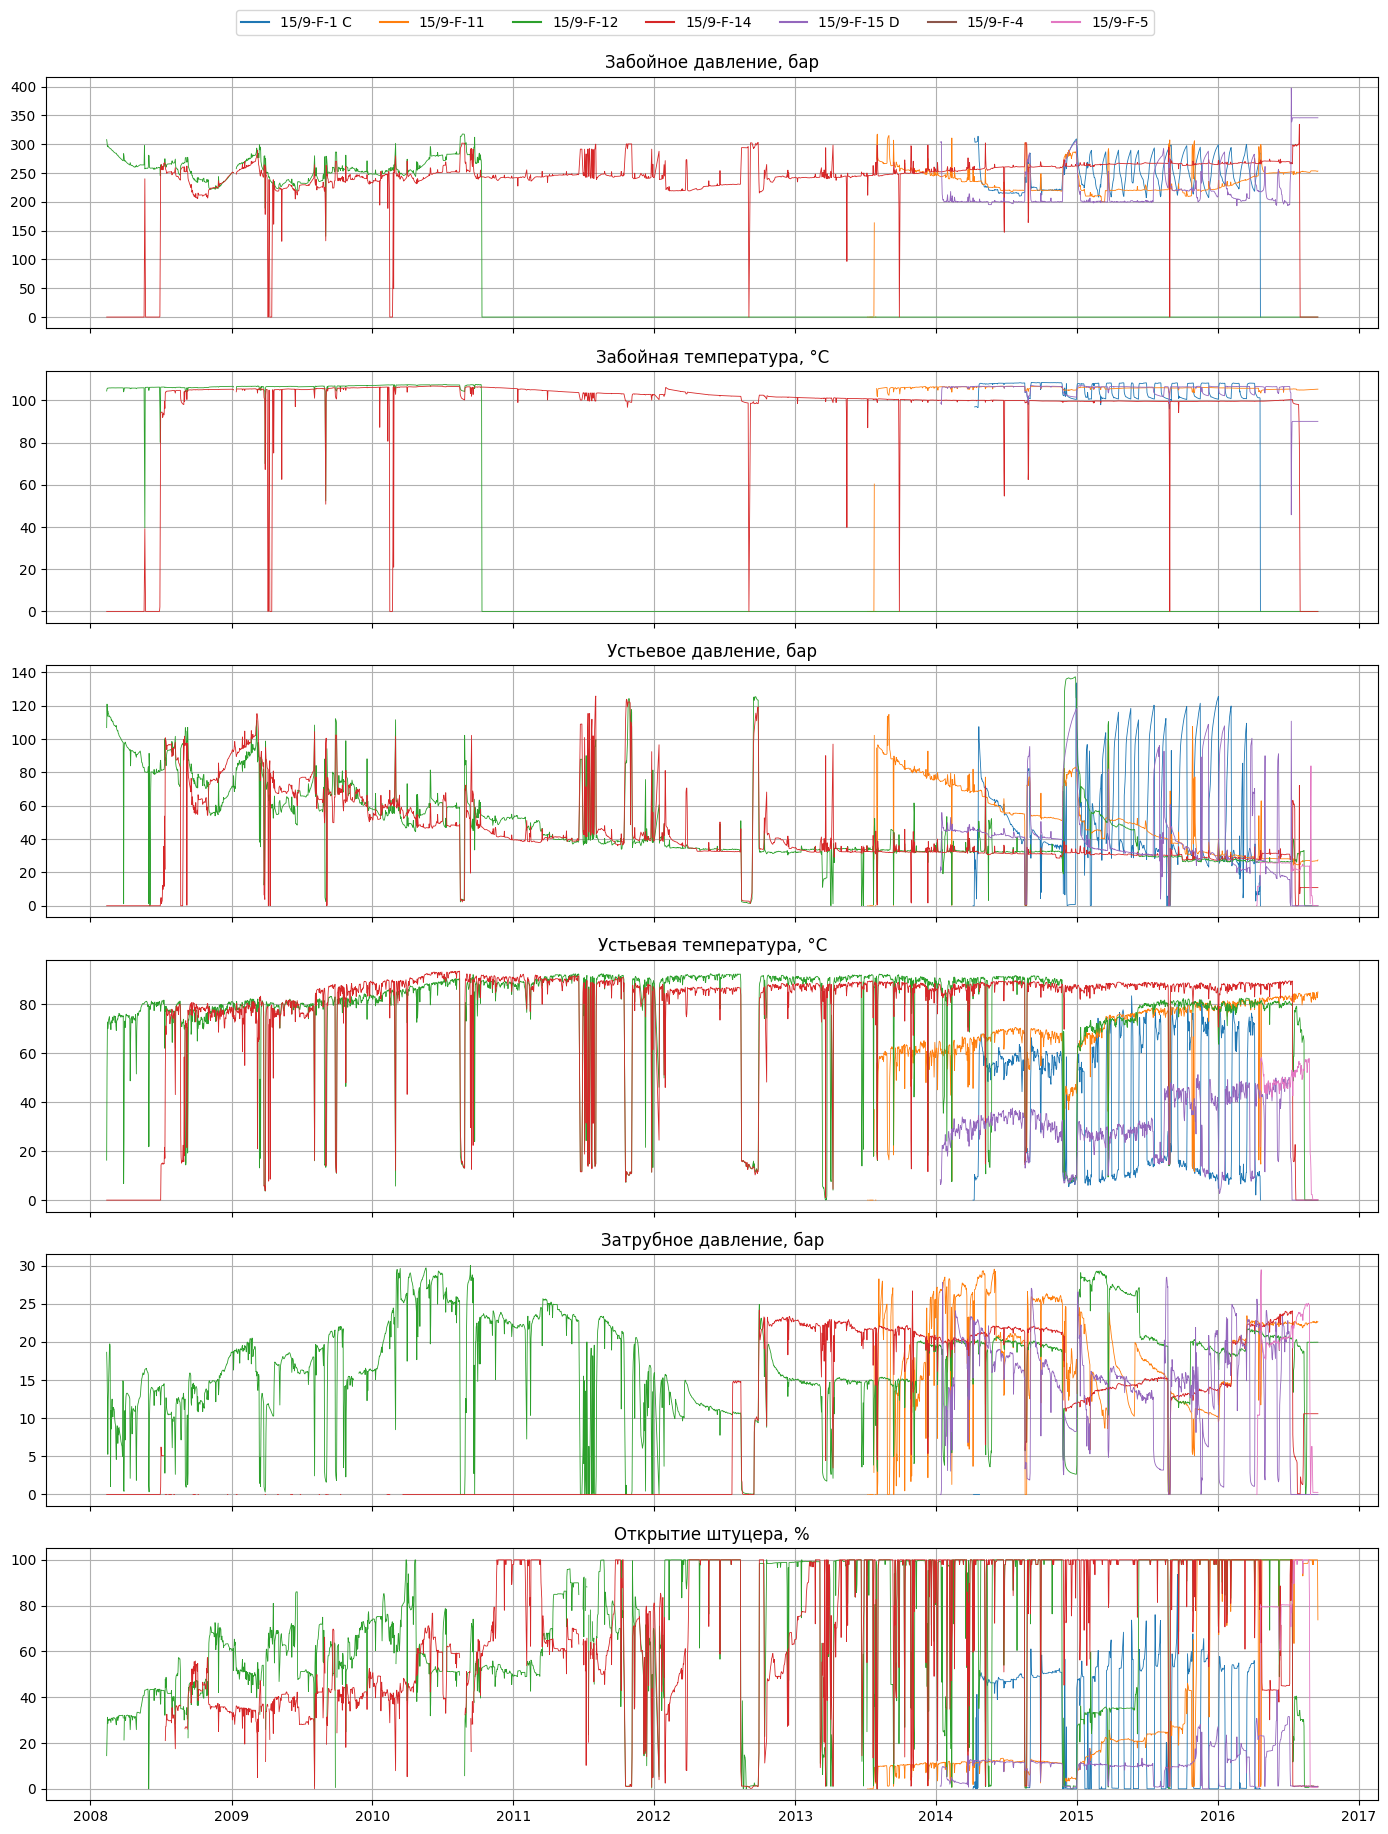

In [15]:
params = [
    ("AVG_DOWNHOLE_PRESSURE", "Забойное давление, бар"),
    ("AVG_DOWNHOLE_TEMPERATURE", "Забойная температура, °C"),
    ("AVG_WHP_P", "Устьевое давление, бар"),
    ("AVG_WHT_P", "Устьевая температура, °C"),
    ("AVG_ANNULUS_PRESS", "Затрубное давление, бар"),
    ("AVG_CHOKE_SIZE_P", "Открытие штуцера, %"),
]

fig, axes = plt.subplots(len(params), 1, figsize=(14, 3 * len(params)), sharex=True)
for ax, (col, title) in zip(axes, params):
    for well, g in daily.groupby("NPD_WELL_BORE_NAME"):
        ax.plot(g["DATEPRD"], g[col], lw=0.6, color=WELL_COLORS[well], label=well)
    ax.set_title(title)
fig.legend(handles=[plt.Line2D([], [], color=c, label=w) for w, c in WELL_COLORS.items()],
           ncol=len(WELL_COLORS), loc="upper center", bbox_to_anchor=(0.5, 1.02))
plt.tight_layout()
plt.show()

### Распределения числовых параметров (только ненулевые значения)

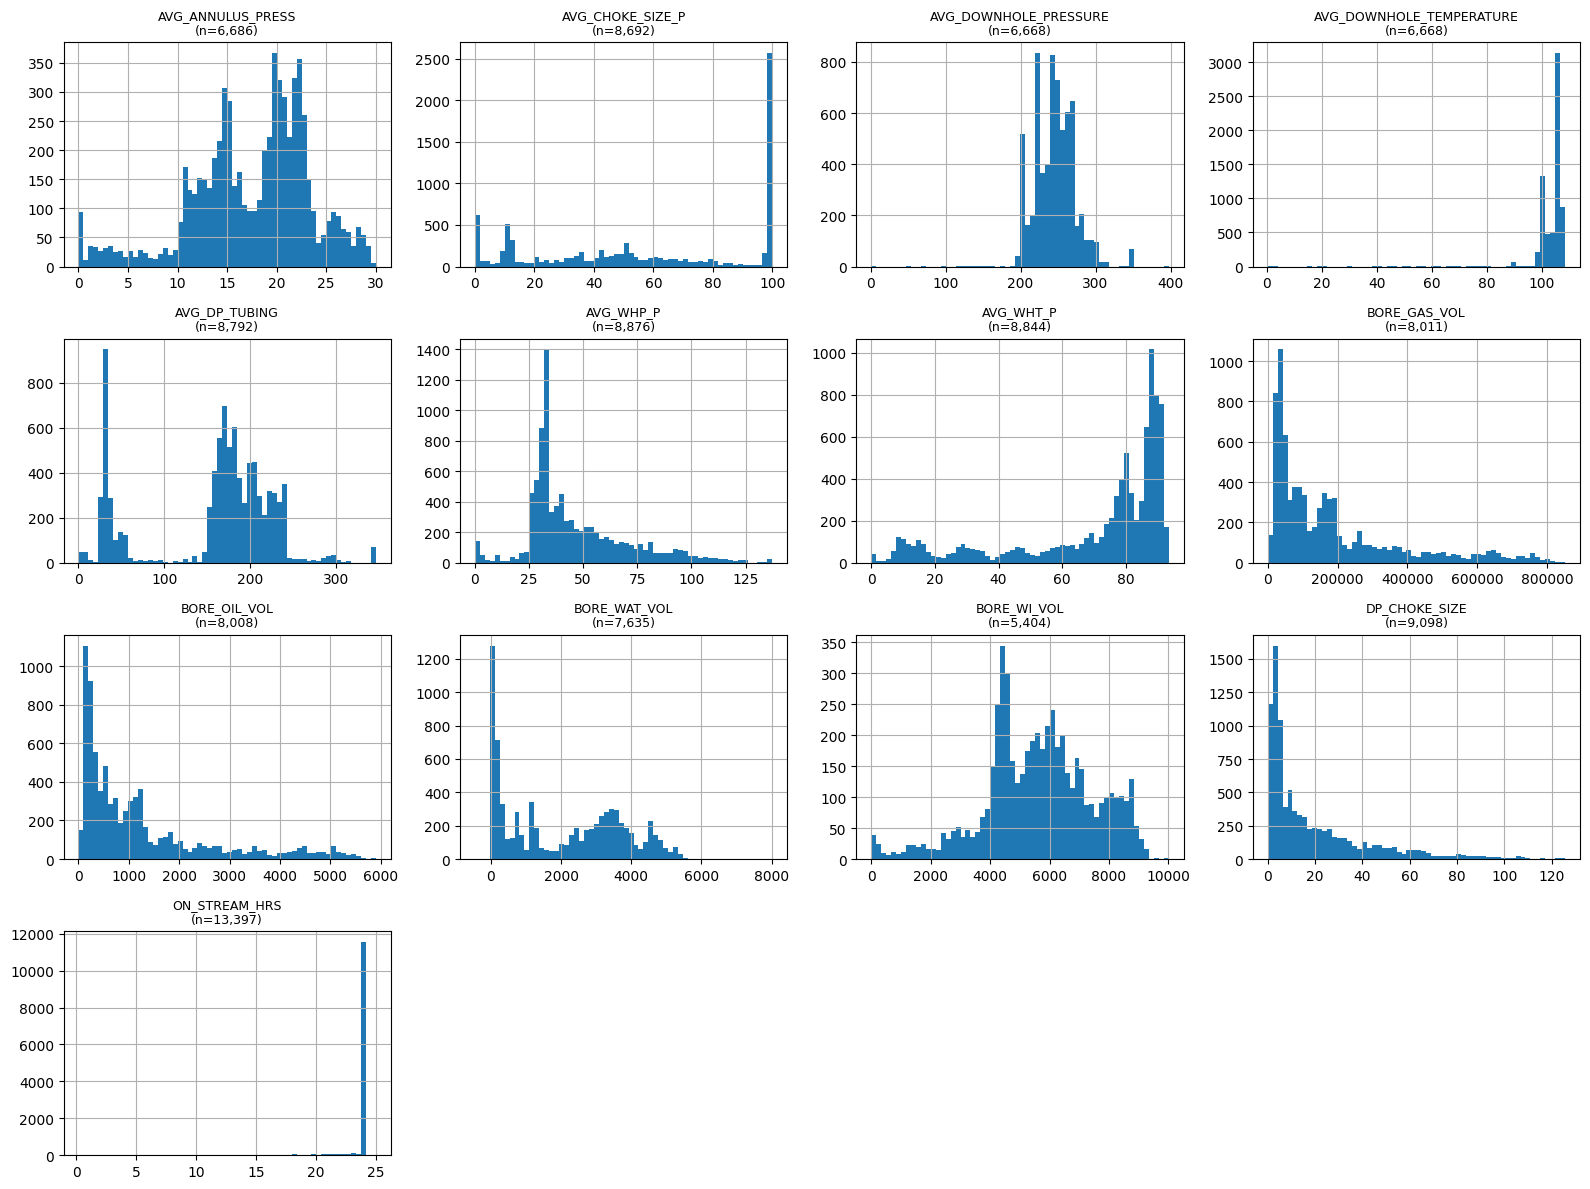

In [16]:
ncols = 4
nrows = int(np.ceil(len(NUM_COLS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3 * nrows))
for ax, col in zip(axes.flat, NUM_COLS):
    values = daily[col].dropna()
    values = values[values != 0]
    ax.hist(values, bins=60)
    ax.set_title(f"{col}\n(n={len(values):,})", fontsize=9)
for ax in axes.flat[len(NUM_COLS):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Корреляции параметров (добывающие скважины, ON_STREAM_HRS > 0)

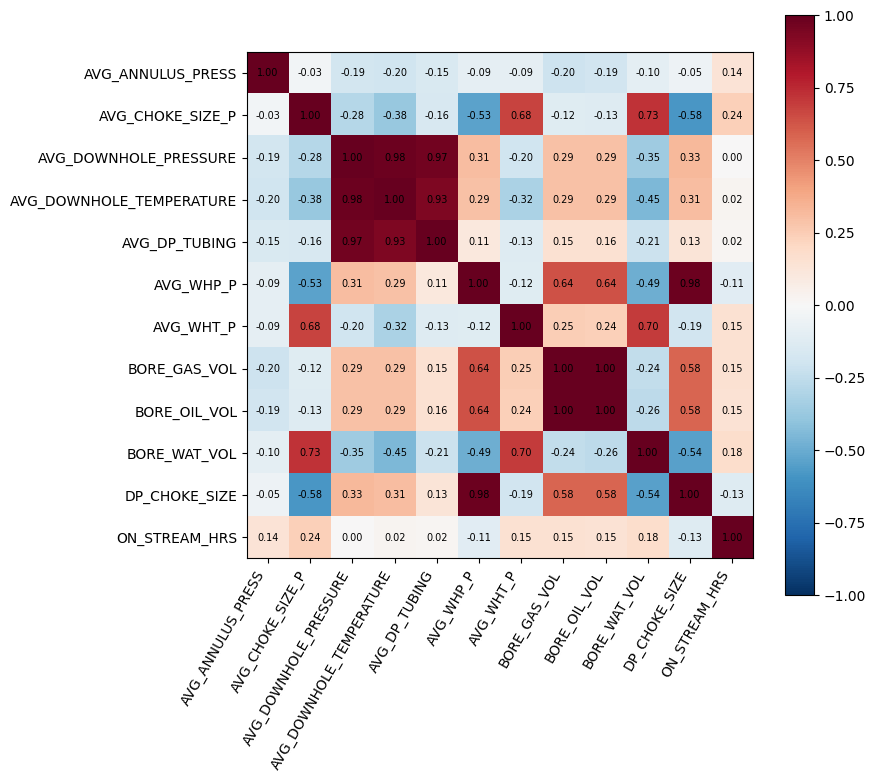

In [17]:
prod = daily[(daily["FLOW_KIND"] == "production") & (daily["ON_STREAM_HRS"] > 0)]
corr_cols = [c for c in NUM_COLS if c != "BORE_WI_VOL"]
corr = prod[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=60, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## Месячные данные

Первая строка листа содержит единицы измерения, а не данные — выносим её отдельно и приводим колонки к числам.

In [20]:
units_row = monthly_raw.iloc[0]
monthly_units = units_row.dropna().to_dict()
print("Единицы:", monthly_units)

monthly = monthly_raw.iloc[1:].copy()
monthly = monthly.dropna(how="all")
value_cols = ["On Stream", "Oil", "Gas", "Water", "GI", "WI"]
for col in ["NPDCode", "Year", "Month", *value_cols]:
    monthly[col] = pd.to_numeric(monthly[col], errors="coerce")

# Строки без скважины/даты (итоги, примечания) — смотрим отдельно
bad_rows = monthly[monthly[["Wellbore name", "Year", "Month"]].isna().any(axis=1)]
print(f"Строк без скважины или даты: {len(bad_rows)}")
display(bad_rows)

monthly = monthly.drop(bad_rows.index)
monthly[["NPDCode", "Year", "Month"]] = monthly[["NPDCode", "Year", "Month"]].astype(int)
monthly["date"] = pd.to_datetime(dict(year=monthly["Year"], month=monthly["Month"], day=1))
monthly = monthly.reset_index(drop=True)
monthly.head()

Единицы: {'On Stream': 'hrs', 'Oil': 'Sm3', 'Gas': 'Sm3', 'Water': 'Sm3', 'GI': 'Sm3', 'WI': 'Sm3'}
Строк без скважины или даты: 0


,Wellbore name,NPDCode,Year,Month,On Stream,Oil,Gas,Water,GI,WI


,Wellbore name,NPDCode,Year,Month,On Stream,Oil,Gas,Water,GI,WI,date
0,15/9-F-1 C,7405,2014,4,227.50,"11,142.47","1,597,936.65",0.00,NaN,NaN,2014-04-01
1,15/9-F-1 C,7405,2014,5,733.83,"24,901.95","3,496,229.65",783.48,NaN,NaN,2014-05-01
2,15/9-F-1 C,7405,2014,6,705.92,"19,617.76","2,886,661.69","2,068.48",NaN,NaN,2014-06-01
3,15/9-F-1 C,7405,2014,7,742.42,"15,085.68","2,249,365.75","6,243.98",NaN,NaN,2014-07-01
4,15/9-F-1 C,7405,2014,8,432.99,"6,970.43","1,048,190.80","4,529.75",NaN,NaN,2014-08-01


In [21]:
pd.DataFrame({
    "непустых": monthly.notna().sum(),
    "пропусков, %": monthly.isna().mean() * 100,
})

,непустых,"пропусков, %"
Wellbore name,526,0.00
NPDCode,526,0.00
Year,526,0.00
Month,526,0.00
On Stream,515,2.09
Oil,311,40.87
Gas,311,40.87
Water,311,40.87
GI,0,100.00
WI,201,61.79


In [22]:
monthly[value_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
On Stream,515.00,595.90,196.68,0.00,561.33,683.74,720.00,745.00
Oil,311.00,"32,273.57","37,361.94",0.00,"6,085.66","17,870.72","37,607.39","166,439.67"
Gas,311.00,"4,743,956.39","5,302,562.27",0.00,"923,652.24","2,722,573.45","5,780,979.75","24,106,361.74"
Water,311.00,"49,255.88","47,458.16",0.00,"3,534.34","36,195.93","94,056.46","155,365.68"
GI,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WI,201.00,"150,896.19","56,431.41",0.00,"126,376.88","150,430.99","188,426.12","270,199.40"


In [23]:
monthly.groupby("Wellbore name").agg(
    месяцев=("date", "size"),
    начало=("date", "min"),
    конец=("date", "max"),
    нефть=("Oil", "sum"),
    газ=("Gas", "sum"),
    вода=("Water", "sum"),
    закачка_газа=("GI", "sum"),
    закачка_воды=("WI", "sum"),
)

,месяцев,начало,конец,нефть,газ,вода,закачка_газа,закачка_воды
Wellbore name,,,,,,,,
15/9-F-1 C,25,2014-04-01,2016-04-01,"177,709.33","26,440,918.60","207,302.39",0.00,0.00
15/9-F-11,39,2013-07-01,2016-09-01,"1,147,849.10","174,310,520.61","1,090,806.27",0.00,0.00
15/9-F-12,104,2008-02-01,2016-09-01,"4,579,609.55","667,542,278.02","6,833,320.37",0.00,0.00
15/9-F-14,104,2008-02-01,2016-09-01,"3,942,233.39","578,009,542.02","7,121,249.74",0.00,0.00
15/9-F-15 D,33,2014-01-01,2016-09-01,"148,518.56","22,505,350.95","52,366.40",0.00,0.00
15/9-F-4,112,2007-09-01,2016-12-01,0.00,0.00,0.00,0.00,"16,240,727.04"
15/9-F-5,109,2007-09-01,2016-09-01,"41,160.68","6,561,825.74","13,533.18",0.00,"14,089,406.49"


### Добыча по месторождению в целом (сумма по скважинам)

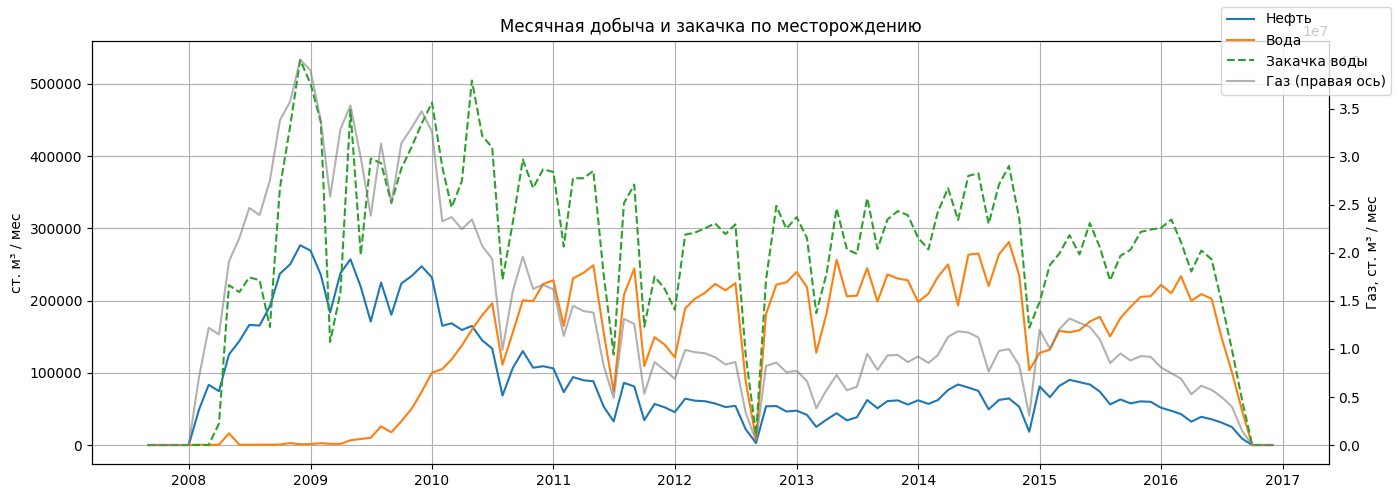

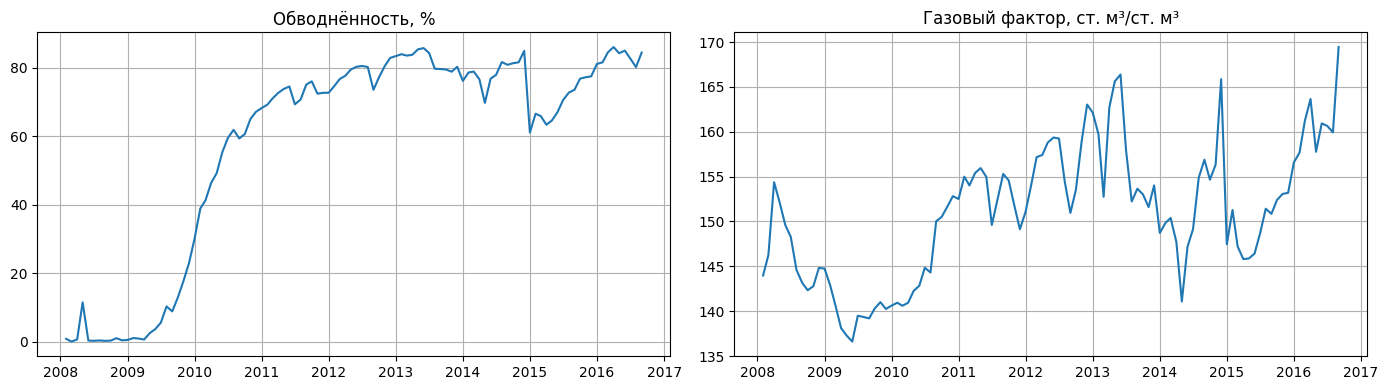

In [24]:
field = monthly.groupby("date")[["Oil", "Gas", "Water", "WI"]].sum()

fig, ax = plt.subplots()
ax.plot(field.index, field["Oil"], label="Нефть")
ax.plot(field.index, field["Water"], label="Вода")
ax.plot(field.index, field["WI"], label="Закачка воды", ls="--")
ax.set_ylabel("ст. м³ / мес")
ax2 = ax.twinx()
ax2.plot(field.index, field["Gas"], color="tab:gray", alpha=0.6, label="Газ (правая ось)")
ax2.set_ylabel("Газ, ст. м³ / мес")
ax2.grid(False)
fig.legend(loc="upper right")
ax.set_title("Месячная добыча и закачка по месторождению")
plt.tight_layout()
plt.show()

water_cut = (field["Water"] / (field["Oil"] + field["Water"])).replace([np.inf, -np.inf], np.nan)
gor = (field["Gas"] / field["Oil"]).replace([np.inf, -np.inf], np.nan)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(water_cut.index, water_cut * 100)
axes[0].set_title("Обводнённость, %")
axes[1].plot(gor.index, gor)
axes[1].set_title("Газовый фактор, ст. м³/ст. м³")
plt.tight_layout()
plt.show()

## Согласованность суточных и месячных данных

Агрегируем суточные данные по месяцам и сравниваем с месячным листом.

In [25]:
daily_agg = (
    daily.assign(date=daily["DATEPRD"].dt.to_period("M").dt.to_timestamp())
    .groupby(["NPD_WELL_BORE_CODE", "date"])
    .agg(
        on_stream_d=("ON_STREAM_HRS", "sum"),
        oil_d=("BORE_OIL_VOL", "sum"),
        gas_d=("BORE_GAS_VOL", "sum"),
        water_d=("BORE_WAT_VOL", "sum"),
        wi_d=("BORE_WI_VOL", "sum"),
    )
    .reset_index()
)

cmp = monthly.merge(
    daily_agg,
    left_on=["NPDCode", "date"],
    right_on=["NPD_WELL_BORE_CODE", "date"],
    how="outer",
    indicator=True,
)
print(cmp["_merge"].value_counts().rename({"left_only": "только месячные", "right_only": "только суточные"}))

pairs = [("On Stream", "on_stream_d"), ("Oil", "oil_d"), ("Gas", "gas_d"), ("Water", "water_d"), ("WI", "wi_d")]
both = cmp[cmp["_merge"] == "both"]
summary = {}
for m_col, d_col in pairs:
    m, d = both[m_col].fillna(0), both[d_col].fillna(0)
    rel = (m - d).abs() / m.abs().clip(lower=1)
    summary[m_col] = {
        "сумма (месячные)": m.sum(),
        "сумма (суточные)": d.sum(),
        "отклонение суммы, %": (d.sum() - m.sum()) / m.sum() * 100 if m.sum() else np.nan,
        "месяцев с расхождением > 5%": (rel > 0.05).sum(),
    }
pd.DataFrame(summary).T

_merge
both               526
только месячные      0
только суточные      0
Name: count, dtype: int64


,сумма (месячные),сумма (суточные),"отклонение суммы, %",месяцев с расхождением > 5%
On Stream,"306,889.34","306,889.34",0.00,0.00
Oil,"10,037,080.61","10,037,080.61",0.00,0.00
Gas,"1,475,370,435.94","1,475,370,435.94",0.00,0.00
Water,"15,318,578.35","15,318,578.35",0.00,0.00
WI,"30,330,133.53","30,330,133.53",-0.00,0.00


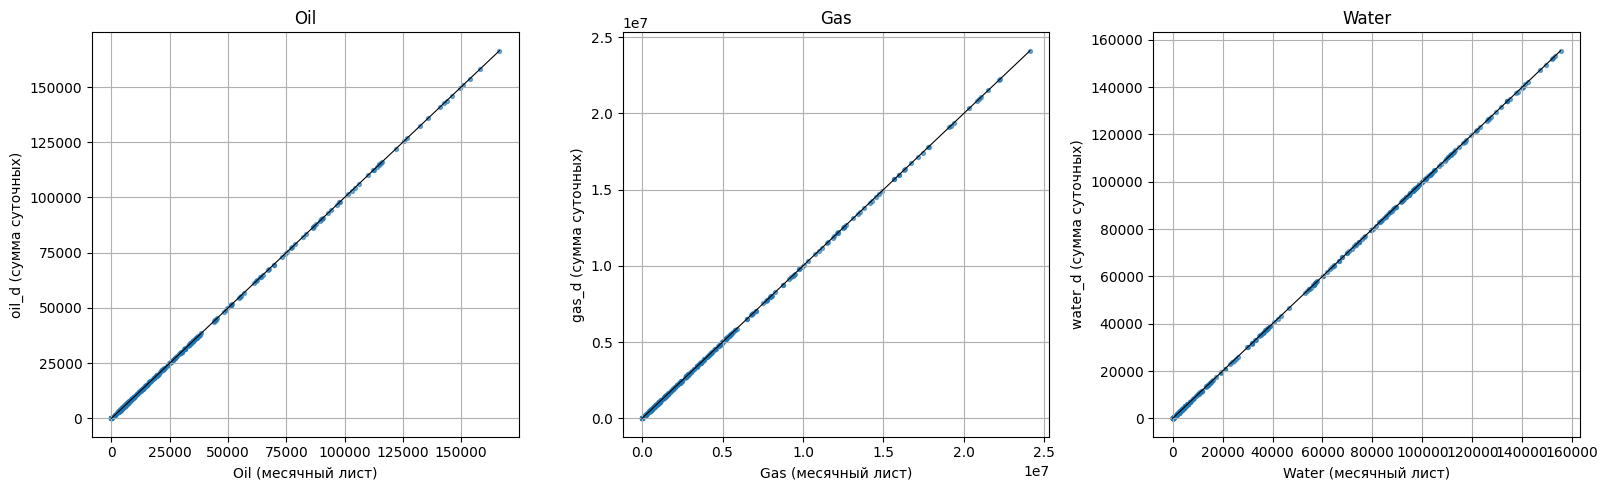

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (m_col, d_col) in zip(axes, pairs[1:4]):
    ax.scatter(both[m_col], both[d_col], s=8, alpha=0.6)
    lim = np.nanmax([both[m_col].max(), both[d_col].max()])
    ax.plot([0, lim], [0, lim], color="k", lw=0.8)
    ax.set_xlabel(f"{m_col} (месячный лист)")
    ax.set_ylabel(f"{d_col} (сумма суточных)")
    ax.set_title(m_col)
plt.tight_layout()
plt.show()

## Итоги обзора

Заполните после запуска: основные наблюдения о качестве данных, пропусках, расхождениях между листами
и о том, какие колонки/скважины/периоды стоит использовать дальше.